# Evaluation der Imputationsmethoden - Visualisierung

Ergänzt die textuelle Auswertung aus
[impute_missing_values.py](impute_missing_values.py) (Methoden 1/2/3/4, siehe
dortiger Modul-Docstring) um Visualisierungen der Fehlerverteilungen sowie
zusätzliche Kennzahlen (Median, Std, P90/P95), die im Skript bereits
mitausgegeben, hier aber zusätzlich grafisch dargestellt werden - insbesondere
zur Einordnung von Methode 2 (naive Fortschreibung), die dort als triviale
Baseline mitevaluiert wird.

Führt dieselbe Leave-one-out-Evaluation mit identischem Seed erneut aus und
reicht keine neue Schätzlogik nach - reine Darstellung der Ergebnisse aus dem
Skript.

In [1]:
import warnings

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import psycopg2

import impute_missing_values as imp

warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy connectable")

# Verbindungsdaten wie im Skript - per PGHOST/PGPORT/PGDATABASE/PGUSER/PGPASSWORD
# überschreibbar (siehe analysis/data-analysis/AGENTS.md).
conn = psycopg2.connect(
    host=imp.PGHOST, port=imp.PGPORT, dbname=imp.PGDATABASE,
    user=imp.PGUSER, password=imp.PGPASSWORD,
)
pivots = imp.load_pivots(conn)
conn.close()
len(pivots), list(pivots)

(13,
 ['arbeitslose',
  'arbeitsvolumen',
  'auszubildende',
  'bevoelkerung',
  'bruttoverdienst',
  'durchschnittsalter',
  'erwerbstaetige',
  'kinderarmut',
  'medianeinkommen',
  'schuldnerquote',
  'sgb_ii_quote',
  'studierende',
  'wohngeldhaushalte'])

## Leave-one-out-Evaluation

Identisch zu `run_evaluation()` / `summarize_evaluation()` im Skript - die
textuellen Tabellen (inkl. der zusätzlichen Kennzahlen Median AE, Std, P90/P95,
Max) erscheinen hier als Referenz, die folgenden Zellen visualisieren dieselben
Daten.

In [2]:
eval_df = imp.run_evaluation(pivots, n_per_dataset=40, seed=42)
overall, win_table, per_dataset = imp.summarize_evaluation(eval_df)

##############################################################################
# Systematische Evaluation (Leave-one-out, n=520 Stichproben über 13 Datensätze)
##############################################################################

--- Gesamt-Gütemaße je Methode ---
                                 n verfügbar       MAE  Median AE      RMSE  Std (signed err)  MAPE %  Median APE %  Bias (mean signed err)    P90 AE     P95 AE      Max AE
Methode                                                                                                                                                                     
1. Lineare Interpolation                 520    64.068      0.832   268.890           268.020    2.45          0.93                  24.610   108.850    328.575    3524.500
2. Naive Fortschreibung                  520   127.754      1.400   456.896           457.253    4.11          2.03                  -8.719   234.500    930.900    5540.000
3. Peer-basierte Fortschreibung  

In [3]:
METHOD_KEYS = ["1_linear", "2_naive", "3_peer", "4_regression"]
COLORS = {
    "1. Lineare Interpolation": "#2a78d6",
    "2. Naive Fortschreibung": "#9a9a9a",
    "3. Peer-basierte Fortschreibung": "#2f9e44",
    "4. Regressionsschätzung": "#d03b3b",
}
METHOD_LABELS = list(COLORS.keys())


def short_label(label: str) -> str:
    return label.split(". ", 1)[1]

## Mittlerer vs. medianer prozentualer Fehler je Methode

Die 13 Kreis-Datensätze liegen auf sehr unterschiedlichen Skalen (Bevölkerung
in Personen, Schuldnerquote in Prozentpunkten, ...) - ein datensatzübergreifender
Vergleich absoluter Fehler (MAE/RMSE) wird daher von den großskaligen
Datensätzen dominiert. MAPE/APE normalisieren auf den jeweiligen Wert und sind
so über alle Datensätze hinweg vergleichbar. Median zusätzlich zum Mittelwert,
weil einzelne extreme Ausreißer (v.a. bei Methode 4) den Mittelwert stark
verzerren können.

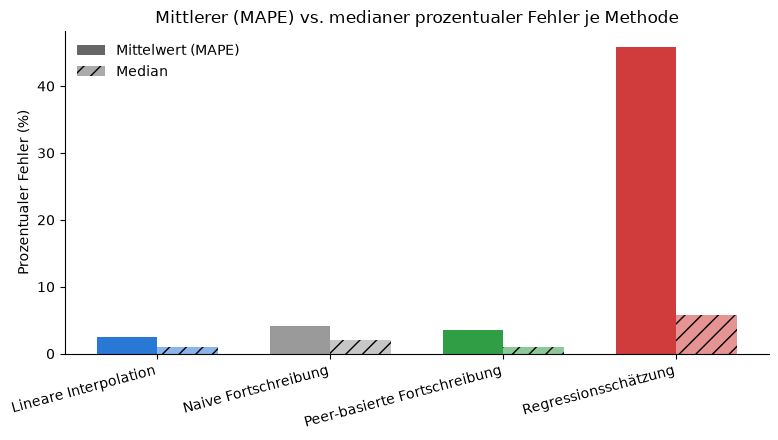

In [4]:
overall_idx = overall.set_index("Methode").loc[METHOD_LABELS]

x = np.arange(len(METHOD_LABELS))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
bars_mean = ax.bar(
    x - width / 2, overall_idx["MAPE %"], width,
    color=[COLORS[m] for m in METHOD_LABELS],
)
bars_median = ax.bar(
    x + width / 2, overall_idx["Median APE %"], width,
    color=[COLORS[m] for m in METHOD_LABELS], alpha=0.55, hatch="//",
)
ax.set_xticks(x)
ax.set_xticklabels([short_label(m) for m in METHOD_LABELS], rotation=15, ha="right")
ax.set_ylabel("Prozentualer Fehler (%)")
ax.set_title("Mittlerer (MAPE) vs. medianer prozentualer Fehler je Methode")
legend_handles = [
    plt.Rectangle((0, 0), 1, 1, fc="#666", alpha=1.0),
    plt.Rectangle((0, 0), 1, 1, fc="#666", alpha=0.55, hatch="//"),
]
ax.legend(legend_handles, ["Mittelwert (MAPE)", "Median"], frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Verteilung der prozentualen Fehler je Methode

Boxplot (log-Skala) über alle Holdout-Stichproben und Datensätze hinweg - zeigt
die volle Streuung statt nur Mittelwert/Median. `showfliers=False` blendet nur
die *Darstellung* einzelner Ausreißerpunkte aus, Box und Whisker werden weiter
aus allen Werten berechnet (Standard-1.5×IQR-Regel).

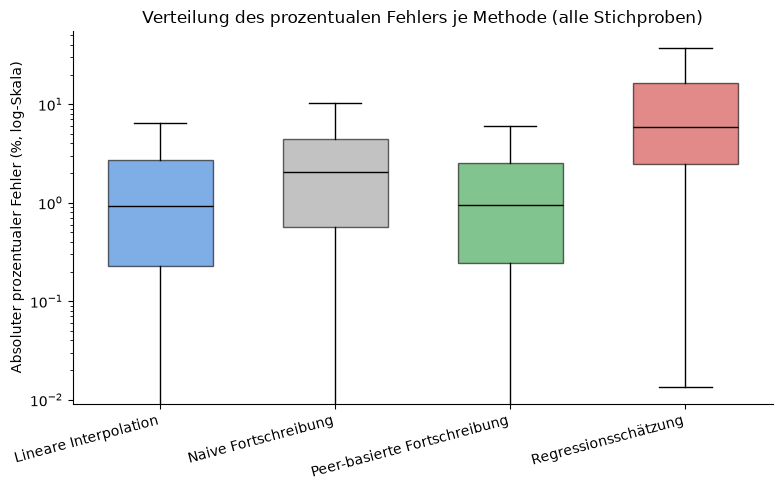

In [5]:
data = [eval_df[f"pct_err_{m}"].dropna() for m in METHOD_KEYS]

fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(
    data, tick_labels=[short_label(m) for m in METHOD_LABELS],
    patch_artist=True, showfliers=False, widths=0.6,
)
for patch, m in zip(bp["boxes"], METHOD_LABELS):
    patch.set_facecolor(COLORS[m])
    patch.set_alpha(0.6)
for median in bp["medians"]:
    median.set_color("black")
ax.set_yscale("log")
ax.set_ylabel("Absoluter prozentualer Fehler (%, log-Skala)")
ax.set_title("Verteilung des prozentualen Fehlers je Methode (alle Stichproben)")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Relative Güte je Datensatz (gegenüber linearer Interpolation)

Verhältnis `MAE(Methode) / MAE(Methode 1)` je Datensatz, dargestellt als
`log2`-Verhältnis (0 = gleich gut wie Methode 1, negativ/grün = besser,
positiv/rot = schlechter) - ein Verhältnis ist multiplikativ, log-Skalierung
macht "doppelt so schlecht" und "halb so schlecht" symmetrisch in der
Farbskala. Die Zellbeschriftung zeigt das tatsächliche (nicht logarithmierte)
Verhältnis.

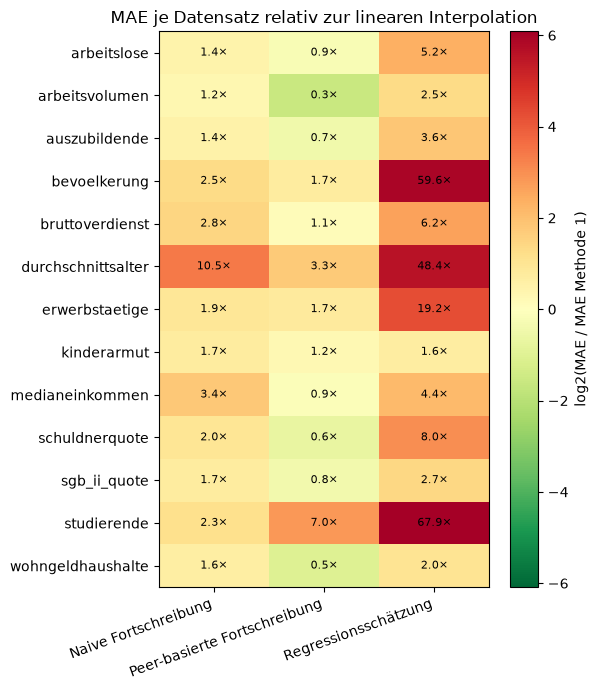

In [6]:
per_dataset_idx = per_dataset.set_index("dataset")
compare_cols = [m for m in METHOD_LABELS if m != "1. Lineare Interpolation"]
ratio = per_dataset_idx[compare_cols].div(per_dataset_idx["1. Lineare Interpolation"], axis=0)
log_ratio = np.log2(ratio)

vmax = float(np.nanmax(np.abs(log_ratio.to_numpy())))
norm = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)

fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(log_ratio.to_numpy(), cmap="RdYlGn_r", norm=norm, aspect="auto")
ax.set_xticks(range(len(compare_cols)))
ax.set_xticklabels([short_label(m) for m in compare_cols], rotation=20, ha="right")
ax.set_yticks(range(len(ratio.index)))
ax.set_yticklabels(ratio.index)
for i in range(ratio.shape[0]):
    for j in range(ratio.shape[1]):
        ax.text(j, i, f"{ratio.iat[i, j]:.1f}\u00d7", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="log2(MAE / MAE Methode 1)")
ax.set_title("MAE je Datensatz relativ zur linearen Interpolation")
plt.tight_layout()
plt.show()

## Trefferquote je Methode

Anteil der Holdout-Stichproben, bei denen die jeweilige Methode den kleinsten
absoluten Fehler hatte (nur Stichproben, bei denen alle vier Methoden
verfügbar waren).

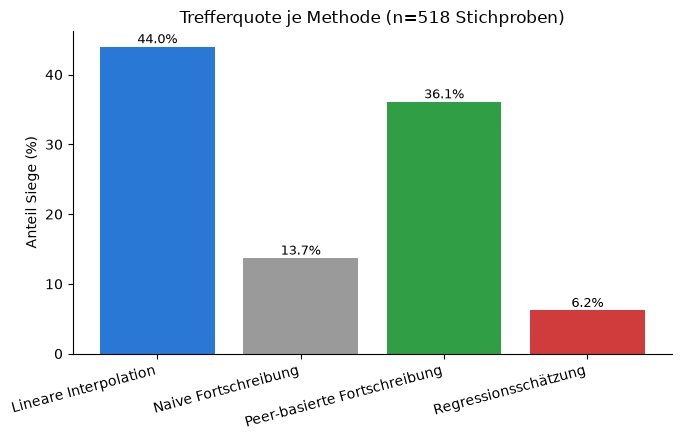

In [7]:
win_table_idx = win_table.set_index("Methode").loc[METHOD_LABELS]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(len(METHOD_LABELS)), win_table_idx["Anteil %"], color=[COLORS[m] for m in METHOD_LABELS])
ax.set_xticks(range(len(METHOD_LABELS)))
ax.set_xticklabels([short_label(m) for m in METHOD_LABELS], rotation=15, ha="right")
ax.set_ylabel("Anteil Siege (%)")
n_total = int(win_table_idx["Anzahl Siege"].sum())
ax.set_title(f"Trefferquote je Methode (n={n_total} Stichproben)")
for i, v in enumerate(win_table_idx["Anteil %"]):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Fazit

- **Naive Fortschreibung (2) ist in allen 13 Datensätzen schwächer** als
  lineare Interpolation (1) - sie bestätigt sich als triviale, aber nicht
  wertlose Baseline: sie gewinnt trotzdem in ~14% der Einzelfälle (v.a. dort,
  wo Trend oder Nachbarregionen irreführen).
- **Lineare Interpolation (1)** gewinnt am häufigsten (~44%), dicht gefolgt von
  der **peer-basierten Fortschreibung (3)** (~36%) - beide sind sich in Median
  AE/APE sehr ähnlich, Methode 3 hat aber einen spürbaren positiven Bias
  (systematische Überschätzung), während Methode 1 nahezu unverzerrt ist.
- **Regression (4)** hat trotz brauchbarer In-Sample-R² in Einzelfällen die mit
  Abstand höchste Fehlerspanne (P95/Max) und die niedrigste Trefferquote
  (~6%) - vor allem bei `bevoelkerung` extrapoliert sie weit außerhalb des
  Trainingsbereichs und produziert Ausreißer um mehrere Größenordnungen. Für
  die produktive Lückenfüllung (siehe
  `render_nuts3_fill_gaps_view.sql`) sind Methode 1 und 3 damit die
  robusteren Kandidaten, Methode 4 eher als Plausibilitäts-Zusatzsignal
  geeignet.